# Analyse multidimensionnelle des signaux de priorisation

Ce notebook analyse les sujets d'intérêt gouvernemental détectés à partir
des publications Facebook selon plusieurs dimensions observables :

- le volume de discussion ;
- l'intensité des réactions ;
- la tonalité des commentaires ;
- le nombre de publications associées ;
- la disponibilité des données d'engagement.

L'objectif est de conserver des indicateurs distincts et interprétables,
plutôt que de réduire la priorisation à un score unique arbitraire.

In [1]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path.cwd().parent

DATA_DIR = (
    PROJECT_DIR
    / "datasets"
    / "facebook"
    / "processed"
)

FILE = DATA_DIR / "Data_Topics_Priority_Indicators.xlsx"

topics = pd.read_excel(FILE)

print("Fichier :", FILE)
print("Nombre de sujets :", len(topics))

topics.head()

Fichier : c:\Users\ouedr\Desktop\memoire_priorisation\datasets\facebook\processed\Data_Topics_Priority_Indicators.xlsx
Nombre de sujets : 17


,topicCluster,mainDomain,representativePostId,representativeText,numberOfPosts,collectedComments,usableComments,commentCoverageRate,discussionIntensity,reactionDocumentation,...,postsWithSharesData,sharesSumAvailable,sharesCoverageRate,postsWithPlatformCommentCount,platformCommentCountSumAvailable,platformCommentsCoverageRate,hasDiscussionSignal,hasSentimentSignal,hasLikesSignal,hasSharesSignal
0,TOPIC_010,SANTE,RECONSTRUCTED_003,"Troubles sexuels : Tabous, automédication et ...",1,20,17,0.850000,2.890372,PLUS_DOCUMENTEE,...,0,NaN,0.0,1,20,1,True,True,False,False
1,TOPIC_001,SCIENCE_TECHNOLOGIE_INNOVATION,1520308410137966,‎CONCOURS NATIONAL DE DÉTECTION DE TALENTS SCI...,2,22,15,0.681818,2.772589,PLUS_DOCUMENTEE,...,1,86.0,0.5,2,33,1,True,True,True,True
2,TOPIC_012,INFRASTRUCTURES_TRANSPORT,RECONSTRUCTED_005,Sécurité routière : L’ONASER traque les compor...,1,12,8,0.666667,2.197225,MODEREE,...,0,NaN,0.0,1,12,1,True,True,False,False
3,TOPIC_002,AGRICULTURE_ELEVAGE_ALIMENTATION,RECONSTRUCTED_007,"Burkina Faso : Aliou Diongue, un expert aguerr...",1,7,4,0.571429,1.609438,FAIBLE,...,0,NaN,0.0,1,7,1,True,True,False,False
4,TOPIC_004,ADMINISTRATION_GOUVERNANCE,RECONSTRUCTED_012,♦️Annonce | Le nouveau code général des collec...,2,4,3,0.750000,1.386294,FAIBLE,...,0,NaN,0.0,2,4,1,True,True,False,False


In [2]:
print("Fichier chargé :")
print(FILE)

print("\nDimensions du fichier :")
print(topics.shape)

print("\nNombre de topicCluster uniques :")
print(topics["topicCluster"].nunique())

print("\nListe des sujets :")
print(topics["topicCluster"].tolist())

Fichier chargé :
c:\Users\ouedr\Desktop\memoire_priorisation\datasets\facebook\processed\Data_Topics_Priority_Indicators.xlsx

Dimensions du fichier :
(17, 34)

Nombre de topicCluster uniques :
17

Liste des sujets :
['TOPIC_010', 'TOPIC_001', 'TOPIC_012', 'TOPIC_002', 'TOPIC_004', 'TOPIC_014', 'TOPIC_007', 'TOPIC_005', 'TOPIC_006', 'TOPIC_017', 'TOPIC_013', 'TOPIC_008', 'TOPIC_003', 'TOPIC_009', 'TOPIC_011', 'TOPIC_015', 'TOPIC_016']


In [3]:
print(topics["reactionDocumentation"].value_counts())

print("\nTotal :")
print(topics["reactionDocumentation"].value_counts().sum())

reactionDocumentation
TRES_FAIBLE        6
AUCUNE_REACTION    5
FAIBLE             3
PLUS_DOCUMENTEE    2
MODEREE            1
Name: count, dtype: int64

Total :
17


## Lecture croisée des signaux

Le volume de discussion et la tonalité des réactions sont analysés
conjointement afin d'éviter qu'un indicateur isolé soit interprété
comme une mesure suffisante de priorité.

Un taux élevé de commentaires négatifs basé sur un très faible nombre
de commentaires doit notamment être interprété avec prudence.

Cette représentation constitue donc une aide à la lecture des signaux
observés dans le corpus et non un classement des sujets.

In [5]:
priority_view = topics[
    [
        "topicCluster",
        "mainDomain",
        "representativeText",
        "numberOfPosts",
        "usableComments",
        "analyzedComments",
        "negativeRate",
        "positiveRate",
        "neutralRate",
        "expressedReactionRate",
        "meanSentiment",
        "meanSentimentConfidence",
        "reactionDocumentation"
    ]
].copy()

print("Nombre de sujets dans priority_view :", len(priority_view))

Nombre de sujets dans priority_view : 17


In [6]:
import re

def create_topic_label(text, max_words=9):

    if pd.isna(text):
        return "Sujet non renseigné"

    text = str(text)

    text = re.sub(
        r"https?://\S+",
        "",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    words = text.split()

    if len(words) > max_words:
        return " ".join(words[:max_words]) + "…"

    return text


priority_view["topicLabel"] = (
    priority_view["representativeText"]
    .apply(create_topic_label)
)

print("Libellés créés :", priority_view["topicLabel"].notna().sum())

Libellés créés : 17


In [7]:
matrix_data = priority_view[
    priority_view["analyzedComments"] > 0
].copy()

matrix_table = matrix_data[
    [
        "topicCluster",
        "topicLabel",
        "usableComments",
        "analyzedComments",
        "negativeRate",
        "reactionDocumentation"
    ]
].sort_values(
    "usableComments",
    ascending=False
)

print("Nombre de sujets avec réactions analysées :", len(matrix_table))

matrix_table

Nombre de sujets avec réactions analysées : 12


,topicCluster,topicLabel,usableComments,analyzedComments,negativeRate,reactionDocumentation
0,TOPIC_010,"Troubles sexuels : Tabous, automédication et r...",17,17,0.117647,PLUS_DOCUMENTEE
1,TOPIC_001,‎CONCOURS NATIONAL DE DÉTECTION DE TALENTS SCI...,15,15,0.133333,PLUS_DOCUMENTEE
2,TOPIC_012,Sécurité routière : L’ONASER traque les compor...,8,8,0.625000,MODEREE
3,TOPIC_002,"Burkina Faso : Aliou Diongue, un expert aguerr...",4,4,0.500000,FAIBLE
4,TOPIC_004,♦️Annonce | Le nouveau code général des collec...,3,3,0.000000,FAIBLE
5,TOPIC_014,Résultats provisoires de l’avis d’appel d’offr...,3,3,0.000000,FAIBLE
6,TOPIC_007,Lutte contre le vol de bétail : Le Burkina…,2,2,0.000000,TRES_FAIBLE
7,TOPIC_005,Sakoula : Une association offre des kits scola...,2,2,0.000000,TRES_FAIBLE
8,TOPIC_006,Burkina Faso : Des chercheurs identifient les ...,2,2,0.000000,TRES_FAIBLE
9,TOPIC_017,Recherche scientifique et souveraineté sanitai...,1,1,1.000000,TRES_FAIBLE


## Matrice des signaux observés

Cette représentation croise deux dimensions :

- l'attention observée, mesurée par le nombre de commentaires exploitables ;
- la tonalité négative observée, mesurée par la proportion de commentaires
  classés négatifs.

La taille des points représente le nombre de commentaires effectivement
analysés. Elle permet de distinguer les résultats reposant sur plusieurs
observations de ceux reposant sur un très faible nombre de commentaires.

Cette matrice ne constitue pas un classement des sujets.

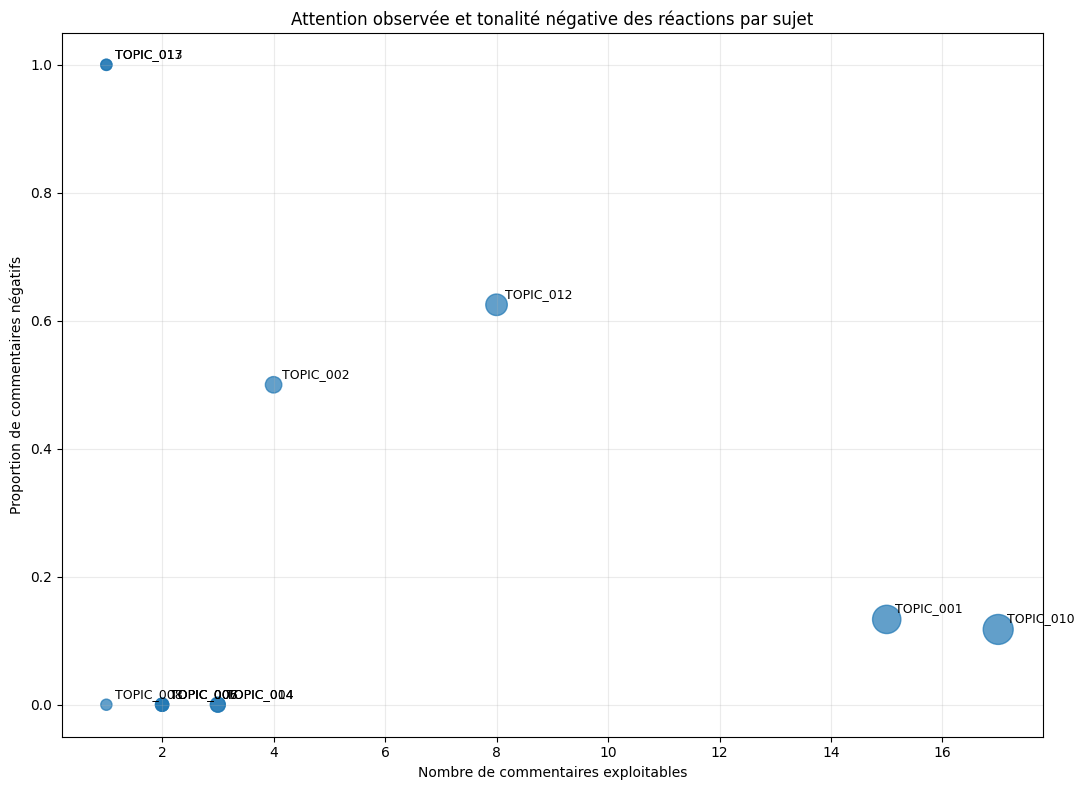

In [8]:
plt.figure(figsize=(11, 8))

plt.scatter(
    matrix_data["usableComments"],
    matrix_data["negativeRate"],
    s=matrix_data["analyzedComments"] * 25 + 40,
    alpha=0.7
)

for _, row in matrix_data.iterrows():
    plt.annotate(
        row["topicCluster"],
        (
            row["usableComments"],
            row["negativeRate"]
        ),
        xytext=(6, 5),
        textcoords="offset points",
        fontsize=9
    )

plt.xlabel("Nombre de commentaires exploitables")
plt.ylabel("Proportion de commentaires négatifs")

plt.title(
    "Attention observée et tonalité négative des réactions par sujet"
)

plt.grid(
    alpha=0.25
)

plt.tight_layout()
plt.show()

In [9]:
without_reactions = priority_view[
    priority_view["analyzedComments"] == 0
][
    [
        "topicCluster",
        "topicLabel",
        "mainDomain",
        "numberOfPosts"
    ]
].copy()

print(
    "Sujets sans commentaire analysable :",
    len(without_reactions)
)

without_reactions

Sujets sans commentaire analysable : 5


,topicCluster,topicLabel,mainDomain,numberOfPosts
12,TOPIC_003,Grande finale de la première édition de la Coupe…,ADMINISTRATION_GOUVERNANCE,2
13,TOPIC_009,MODERNISATION DES INFRASTRUCTURES ACADÉMIQUES ...,EDUCATION_FORMATION,1
14,TOPIC_011,: œ ’ ‎ ‎Le Directeur de Cabinet du…,ADMINISTRATION_GOUVERNANCE,1
15,TOPIC_015,Rentrée administrative 2026-2027 : dans les éc...,ADMINISTRATION_GOUVERNANCE,1
16,TOPIC_016,"MINISTERE DE L’ENSEIGNEMENT DE BASE, DE L’ALPH...",ADMINISTRATION_GOUVERNANCE,1


In [10]:
coverage_summary = pd.DataFrame({
    "Situation": [
        "Avec réactions analysées",
        "Sans réaction analysée"
    ],
    "Nombre de sujets": [
        int((priority_view["analyzedComments"] > 0).sum()),
        int((priority_view["analyzedComments"] == 0).sum())
    ]
})

coverage_summary

,Situation,Nombre de sujets
0,Avec réactions analysées,12
1,Sans réaction analysée,5
